## CorgiDRP HLC Band 1 Imaging Reduction Tutorial

Welcome to this tutorial on running existing **L1** data from `corgisim` or CGI through the `corgidrp` data reduction pipeline. The input is **HLC Band 1 imaging** data stored as one folder per visit; the output is **L4** reference-differential-imaging (RDI) PSF-subtracted images, produced by running the chain **L1 → L2b → L3 → L4**. The L2a stage is saved in the L1 → L2b recipe.

The notebook follows the end-to-end tests in [`corgidrp/tests/e2e_tests`](https://github.com/roman-corgi/corgidrp/tree/develop/tests/e2e_tests). The L1 data are assumed to be `corgisim`-style files (full frame), but any L1 data with the same header conventions will work.

## Installation
To run this notebook, you will need to install `corgidrp`. The repository stores data files (header definitions, default calibrations, astrometry catalogs) with **Git LFS**. Install Git LFS before cloning `corgidrp`, otherwise `corgidrp` will fail. Instructions for install can be found in the `corgidrp` [Installation Guide](https://corgidrp.readthedocs.io/en/latest/installation.html).

> ⚠️ Note: this notebook was developed against corgidrp 5.1.1. If a function signature differs in your checkout, reference the e2e scripts in `corgidrp/tests/e2e_tests`.

# Overview of the pipeline

| Step | Recipe (`corgidrp/recipe_templates`) | Main operations | Input DRP Calibrations used |
|---|---|---|---|
| L1 → L2b | `l1_to_l2b` | prescan bias subtraction, cosmic-ray detection, nonlinearity correction, conversion to e-, EM gain division, dark subtraction, desmear, CTI correction, flat division, bad pixel correction | DetectorNoiseMaps, DetectorParams, KGain, NonLinearityCalibration, TrapCalibration, FlatField, BadPixelMap |
| L2b → L3 | `l2b_to_l3` | discard setup frames, WCS, division by exposure time, crop | AstrometricCalibration |
| L3 → L4 | `l3_to_l4` | bad-pixel replacement, distortion correction, star location, PSF subtraction (pyKLIP), L4 update | AstrometricCalibration, CoreThroughputCalibration, FluxcalFactor |

The pipeline is driven by `corgidrp.walker.walk_corgidrp`, which reads the headers of the input files, picks the recipe, finds each calibration in the calibration database, and runs the steps.

In [1]:
## import packages
import os
import glob
import shutil
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import astropy.time as time

import corgidrp
import corgidrp.data as data
import corgidrp.mocks as mocks
import corgidrp.caldb as caldb
import corgidrp.detector as detector
import corgidrp.astrom as astrom
import corgidrp.walker as walker
from corgidrp import corethroughput

#### Step 0: Input and output directories

`parent_dir` is the folder that contains the visit folders (`V0200001001001001001`, ..., `V0200001001001001011`). All pipeline products are written under `base_dir`, with one sub-folder per processing level.

In [2]:
parent_dir = '/Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/upsAnd_scenario' # edit with path to directory containing visit folders V02000010010010010xx

base_dir = os.path.join(parent_dir, 'l1_to_l4_tutorial')   # output location
cal_dir  = os.path.join(base_dir, 'calibrations')
l2b_dir  = os.path.join(base_dir, 'l1_to_l2b')
l3_dir   = os.path.join(base_dir, 'l2b_to_l3')
l4_dir   = os.path.join(base_dir, 'l3_to_l4')
for d in [base_dir, cal_dir, l2b_dir, l3_dir, l4_dir]:
    os.makedirs(d, exist_ok=True)

### Step 1: Read the L1 data

We collect every FITS file in the visit folders and summarize each visit from the headers. An RDI reduction needs target visits at two or more roll angles (`PA_APER`) and at least one reference-star visit (`PSFREF=1`). Each visit should also contain satellite-spot frames (`SATSPOTS=1`), which `find_star` uses to locate the star behind the focal plane mask.

In [3]:
visit_dirs = sorted(glob.glob(os.path.join(parent_dir, 'V*')))              # directories for each visit/roll
l1_files = sorted(glob.glob(os.path.join(parent_dir, 'V*', '*.fits')))      # l1 fits files
print(len(visit_dirs), 'visit folders,', len(l1_files), 'L1 files\n')

# Get summary of L1 files in each visit folder
print(f"{'folder':<24}{'frames':>7}{'satspot':>8}{'PSFREF':>7}{'PA_APER':>9}  {'EXPTIME (s)':<14}{'EMGAIN_C':<10}")
for d in visit_dirs:
    files = sorted(glob.glob(os.path.join(d, '*.fits')))
    hdr0 = fits.getheader(files[0], 0)
    hdr1 = [fits.getheader(f, 1) for f in files]
    n_sat = sum(int(h['SATSPOTS']) for h in hdr1)
    exptimes = sorted({h['EXPTIME'] for h in hdr1})
    gains = sorted({h['EMGAIN_C'] for h in hdr1})
    print(f"{os.path.basename(d):<24}{len(files):>7}{n_sat:>8}{hdr0['PSFREF']:>7}{hdr0['PA_APER']:>9.1f}  {str(exptimes):<14}{str(gains):<10}")

11 visit folders, 3421 L1 files

folder                   frames satspot PSFREF  PA_APER  EXPTIME (s)   EMGAIN_C  
V0200001001001001001        319      15      1    122.9  [1.247, 24.217][608.314, 1231.44]
V0200001001001001002        308      15      0    269.3  [9.002, 27.732][603.462, 3860.162]
V0200001001001001003        308      15      0    239.2  [9.002, 27.732][603.462, 3860.162]
V0200001001001001004        308      15      0    269.1  [9.002, 27.732][603.462, 3860.162]
V0200001001001001005        308      15      0    239.1  [9.002, 27.732][603.462, 3860.162]
V0200001001001001006        319      15      1     92.2  [1.247, 24.217][608.314, 1231.44]
V0200001001001001007        308      15      0    238.9  [9.002, 27.732][603.462, 3860.162]
V0200001001001001008        308      15      0    268.9  [9.002, 27.732][603.462, 3860.162]
V0200001001001001009        308      15      0    238.8  [9.002, 27.732][603.462, 3860.162]
V0200001001001001010        308      15      0    268.8  [9

Check the other header keywords the pipeline relies on in the first frame. `EACQ_ROW/COL` give the star position used to crop the frames at L3, and the mask and filter names (`FPAMNAME`, `CFAMNAME`, `DPAMNAME`, ...) are used to select the recipe and match calibrations.

In [4]:
first_hdr0, first_hdr1 = fits.getheader(l1_files[0], 0), fits.getheader(l1_files[0], 1)
keys = ['EACQ_ROW', 'EACQ_COL', 'FPAMNAME', 'DPAMNAME', 'CFAMNAME', 'LSAMNAME', 'FSAMNAME', 'ISPC', 'KGAINPAR']
print({k: first_hdr1.get(k) for k in keys})
print({k: first_hdr0.get(k) for k in ['VISTYPE', 'VISITID']})

{'EACQ_ROW': 300, 'EACQ_COL': 300, 'FPAMNAME': 'HLC12_C2R5', 'DPAMNAME': 'IMAGING', 'CFAMNAME': '1F', 'LSAMNAME': 'NFOV', 'FSAMNAME': 'R1C1', 'ISPC': 0, 'KGAINPAR': 8.7}
{'VISTYPE': 'CGIVST_TDD_SETUP_HOWFSC', 'VISITID': '0200001001001001001'}


### Step 2: Calibration database and calibration files

corgidrp finds calibrations through a **calibration database** (`CalDB`). We point it at a temporary file so this tutorial does not touch your default database, and register each calibration as we create it.

Real calibrations come from dedicated calibration observations. Here:

- **Built from the values provided below** (these must reproduce how the L1 data were produced): nonlinearity, KGain, DetectorNoiseMaps, FlatField, BadPixelMap.
- **Mocks**: astrometric, core-throughput and flux calibrations. 

In [5]:
# Edit these to match the L1 data.
calib_path = '/Users/shasler/git_repos/corgidrp/corgidrp/data/default_calibs' # default calib file path

nonlin_path = os.path.join(calib_path, 'nonlin_table_240322.txt')    # nonlinearity table (example data: corgidrp/data/default_calibs/nonlin_table_240322.txt)
flat_path   = os.path.join(calib_path, 'flat.fits')                  # 1024 x 1024 image-area flat (example: corgidrp/data/default_calibs/flat.fits)
cic_path = os.path.join(calib_path, 'cic_20240322.fits')             # clock-induced charge (CIC) calibration file 
dark_rate   = os.path.join(calib_path, 'dark_current_20240322.fits') # dark current cal file
fpn_path = os.path.join(calib_path, 'fpn_20240322.fits')             # fixed pattern noise (FPN) cal file
bp_path = os.path.join(calib_path, 'bad_pix.fits')                   # bad pixel cal file
kgain_val    = first_hdr1.get('KGAINPAR', 8.7)                       # e-/DN, taken from the header when present (8.7 is from TVAC)
cfam, fpam  = first_hdr1['CFAMNAME'], first_hdr1['FPAMNAME']         # filter and focal plane mask

In [ ]:
# Initialize connection to calibration database
tmp_caldb_csv = os.path.join(corgidrp.config_folder, 'tmp_tutorial_caldb.csv') # temporary CALDB file database
corgidrp.caldb_filepath = tmp_caldb_csv
if os.path.exists(tmp_caldb_csv): # remove any existing caldb file so CalDB() creates a new one
    os.remove(tmp_caldb_csv)
this_caldb = caldb.CalDB()

# default headers for calibration products; the L1 frames serve as the input dataset
pri_hdr, ext_hdr, err_hdr_default, dq_hdr = mocks.create_default_calibration_product_headers()
ext_hdr['DRPCTIME'] = time.Time.now().isot
ext_hdr['DRPVERSN'] = corgidrp.__version__
mock_input_dataset = data.Dataset(l1_files[-2:-1])

**Nonlinearity and KGain.** The nonlinearity table is read from `nonlin_path`. The PTC array passed to `KGain` is a placeholder, since the pipeline only uses the gain value.

In [7]:
# Nonlinearity calibration
nonlin_cal = data.NonLinearityCalibration(np.genfromtxt(nonlin_path, delimiter=','),
                                      pri_hdr=pri_hdr, ext_hdr=ext_hdr, input_dataset=mock_input_dataset)
mocks.rename_files_to_cgi_format(list_of_fits=[nonlin_cal], output_dir=cal_dir, level_suffix='nln_cal')
this_caldb.create_entry(nonlin_cal)

# K-Gain calibration
signal_arr = np.linspace(0, 50)
noise_arr = np.sqrt(signal_arr)
ptc = np.column_stack([signal_arr, noise_arr])   # placeholder PTC

kgain = data.KGain(kgain_val, ptc=ptc, pri_hdr=pri_hdr, ext_hdr=ext_hdr,
                   input_dataset=mock_input_dataset)
mocks.rename_files_to_cgi_format(list_of_fits=[kgain], output_dir=cal_dir, level_suffix='krn_cal')
this_caldb.create_entry(kgain)

**Detector noise maps.** Three maps on the full 1200 × 2200 frame: fixed-pattern noise (e⁻), clock-induced charge (e⁻/frame) and dark current (e⁻/s). 

In [8]:
with fits.open(cic_path) as hdulist:
        cic_dat = hdulist[0].data
with fits.open(dark_rate) as hdulist:
        dark_dat = hdulist[0].data
with fits.open(fpn_path) as hdulist:
        fpn_dat = hdulist[0].data
with fits.open(bp_path) as hdulist:
        bp_dat = hdulist[0].data

In [9]:
sci = detector.detector_areas['SCI']
noise_map_dat = np.zeros((3, sci['frame_rows'], sci['frame_cols']))
rows, cols, r0c0 = detector.unpack_geom('SCI', 'image')
noise_map_dat[:, r0c0[0]:r0c0[0] + rows, r0c0[1]:r0c0[1] + cols] = np.array([fpn_dat, cic_dat, dark_dat])
noise_map_noise = np.zeros([1,] + list(noise_map_dat.shape))
noise_map_dq = np.zeros(noise_map_dat.shape, dtype=int)

err_hdr = fits.Header()
err_hdr['BUNIT'] = 'detected electron' # units of the array
ext_hdr['B_O'] = 0.                    # bias offset keyword -- will come from real darks in the future
ext_hdr['B_O_ERR'] = 0.                # uncertainty on B_0
ext_hdr['DRPNFILE'] = 6                # of files used to create processed frame
noise_map = data.DetectorNoiseMaps(noise_map_dat, pri_hdr=pri_hdr, ext_hdr=ext_hdr, input_dataset=mock_input_dataset,
                                   err=noise_map_noise, dq=noise_map_dq, err_hdr=err_hdr)
mocks.rename_files_to_cgi_format(list_of_fits=[noise_map], output_dir=cal_dir, level_suffix='dnm_cal')
this_caldb.create_entry(noise_map)

**Flat field and bad-pixel map.** The flat is read from `flat_path`. The default tutorial file assumes no bad pixels, so the map is empty. A `BadPixelMap` is built from a dataset of dark and flat frames.

In [ ]:
# Flat field calibration
flat = data.FlatField(fits.getdata(flat_path).astype(float), pri_hdr=pri_hdr, ext_hdr=ext_hdr, input_dataset=mock_input_dataset)
# flat.ext_hdr['FPAMNAME'] = 'OPEN_12'
# flat.ext_hdr['DPAMNAME'] = 'IMAGING'
mocks.rename_files_to_cgi_format(list_of_fits=[flat], output_dir=cal_dir, level_suffix='flt_cal')
this_caldb.create_entry(flat)

# Bad pixel map -- make sure bpm contains a dark (or dark-like) frame
bp_pri, bp_ext, _, _ = mocks.create_default_calibration_product_headers()
bp_ext['EXPTIME']   = float(mock_input_dataset.frames[0].ext_hdr.get('EXPTIME', 0.0))
bp_ext['EMGAIN_C']  = float(mock_input_dataset.frames[0].ext_hdr.get('EMGAIN_C', 0.0))
bp_ext['DRPNFILE']  = 200
bp_dark = data.Dark(np.zeros_like(bp_dat, dtype=float), pri_hdr=bp_pri, ext_hdr=bp_ext, input_dataset=mock_input_dataset,
                    err=np.zeros((1, ) + bp_dat.shape, dtype=float), dq=np.zeros(bp_dat.shape, dtype='uint16'),
                    err_hdr=fits.Header())
bad_pixel_map = data.BadPixelMap(bp_dat, pri_hdr=pri_hdr, ext_hdr=ext_hdr,
                                 input_dataset=data.Dataset([bp_dark, flat]))
bad_pixel_map.save(filedir=cal_dir)
this_caldb.create_entry(bad_pixel_map)

**Astrometric calibration.** Generate a *mock* astrometric calibration file.

In [11]:
field_path = astrom.default_field_path
astrom_dir = os.path.join(base_dir, 'astrom_cal_input') # directory for astrom cal output
os.makedirs(astrom_dir, exist_ok=True)

rotation = 0 # sets the north angle of the created image (default = 45) 
mock_astrom_dataset = mocks.create_astrom_data(field_path=field_path, filedir=None, rotation=rotation) 
mock_astrom_dataset.save(filedir=astrom_dir)
# perform astrometric calibration -- find_threshold = number of stars to find (default = 10)
astrom_cal = astrom.boresight_calibration(input_dataset=mock_astrom_dataset, field_path=field_path, find_threshold=5)
astrom_cal.save(filedir=cal_dir)
this_caldb.create_entry(astrom_cal)

**Core-throughput and flux calibrations.** The core-throughput calibration is generated from mock PSFs and a mock pupil image. Its `FPAMNAME` is set from the L1 headers so the pipeline matches it to the data. The flux calibration factor is a placeholder value.

In [12]:
# core throughput
pupil_img = np.zeros((1024, 1024))
pupil_img[510:530, 510:530] = 1        # Set to some known value for a select pixel range (as in e2e script)

# Create empty primary header and image extension header with currently defined keywords
prhd, exthd_pupil, errhd, dqhdr = mocks.create_default_L3_headers() 
exthd_pupil.update(CFAMNAME=cfam, DPAMNAME='PUPIL', LSAMNAME='OPEN', FSAMNAME='OPEN', FPAMNAME='OPEN_12') # TODO: set these per configuration
# Create simulated data (individual noiseless 2D gaussians) # TODO: automatically set FWHM?
psf_data, psf_loc_in, half_psf = mocks.create_ct_psfs(50, cfam_name=cfam, n_psfs=100) # 50 = fwhm_mas, n_psfs = number of simulated PSFs

ct_input = [data.Image(pupil_img, pri_hdr=prhd, ext_hdr=exthd_pupil, err=np.ones([1024, 1024])), psf_data[0]]
# Set of off-axis pSFs with a core-thru profile defined 
ct_cal_tmp = corethroughput.generate_ct_cal(data.Dataset(ct_input))
ct_cal_tmp.ext_hdr['FPAMNAME'] = fpam 
mocks.rename_files_to_cgi_format(list_of_fits=[ct_cal_tmp], output_dir=cal_dir, level_suffix='ctm_cal')
this_caldb.create_entry(ct_cal_tmp)

# flux calibration factor (placeholder)
# Create mock cal file
fluxcal_factor = 2e-12
fluxcal_factor_err = 1e-14
pri_ff, ext_ff, err_ff, dq_ff = mocks.create_default_L3_headers()
ext_ff.update(CFAMNAME=cfam, DPAMNAME='PUPIL', LSAMNAME='OPEN', FSAMNAME='OPEN', FPAMNAME='OPEN_12')
flux_cal = data.FluxcalFactor(fluxcal_factor, err=fluxcal_factor_err, pri_hdr=pri_ff, ext_hdr=ext_ff, err_hdr=err_ff,
                              input_dataset=mock_astrom_dataset)
mocks.rename_files_to_cgi_format(list_of_fits=[flux_cal], output_dir=cal_dir, level_suffix='abf_cal')
this_caldb.create_entry(flux_cal)

Found 1 pupil images for the core throughput estimation.
Found 1 off-axis PSFs for the core throughput estimation.


In [13]:
# Get any default cal files that might be needed
# Running this after the previous cells means the ones above are preferentially selected
this_caldb.scan_dir_for_new_entries(corgidrp.default_cal_dir)
print(sorted(os.listdir(cal_dir)))

['cgi_-000000000000000999_20261103t1502101_bpm_cal.fits', 'cgi_-000000000000000999_20261104t1832379_bpm_cal.fits', 'cgi_0200001001001001001_20261103t0948330_dnm_cal.fits', 'cgi_0200001001001001001_20261103t0948330_krn_cal.fits', 'cgi_0200001001001001001_20261103t0948330_nln_cal.fits', 'cgi_0200001001001001001_20261103t0951480_krn_cal.fits', 'cgi_0200001001001001001_20261103t0951480_nln_cal.fits', 'cgi_0200001001001001001_20261103t0952370_dnm_cal.fits', 'cgi_0200001001001001001_20261103t0952370_krn_cal.fits', 'cgi_0200001001001001001_20261103t0952370_nln_cal.fits', 'cgi_0200001001001001001_20261103t1002130_ast_cal.fits', 'cgi_0200001001001001001_20261103t1502101_flt_cal.fits', 'cgi_0200001001001001001_20261103t1502190_abf_cal.fits', 'cgi_0200001001001001001_20261103t1502190_ctm_cal.fits', 'cgi_0200001001001001001_20261103t1503017_abf_cal.fits', 'cgi_0200001001001001001_20261103t1503017_ctm_cal.fits', 'cgi_0200001001001001001_20261104t1320200_dnm_cal.fits', 'cgi_0200001001001001001_20261

### Step 3: Run the pipeline

`walker.walk_corgidrp(filelist, '', output_dir)` inspects the headers of the first file to choose a recipe, looks up the calibrations in the database, runs the steps and saves the results. For L2b and L3 inputs the recipe is chosen automatically. For L1 science data the automatic choice stops at L2a, so we pass `template='l1_to_l2b.json'` to run the full L1 → L2b recipe. The recipe used is also written to the output folder as a `.json` file.

To limit memory use and mirror the e2e script, the frames are processed in groups: **one visit at a time**, with **science and satellite-spot frames** (`SATSPOTS`) and **target and reference** (`PSFREF`) kept apart. The helper below groups files by these header values.

In [15]:
def split_files(filelist):
    # group frames by (visit, target/reference, science/satellite-spot)
    groups = {}
    for f in filelist:
        hdr0, hdr1 = fits.getheader(f, 0), fits.getheader(f, 1)
        key = (hdr0['VISITID'], int(hdr0['PSFREF']), int(hdr1['SATSPOTS']))
        groups.setdefault(key, []).append(f)
    return groups

#### L1 → L2b

The `l1_to_l2b` recipe runs the L2a steps (bias subtraction, cosmic-ray detection, nonlinearity correction) and the L2b steps (conversion to e⁻, EM gain division, dark subtraction, desmear, CTI correction, flat division, bad-pixel correction). The recipe also saves an intermediate L2a file, so `l2b_dir` contains both `*l2a.fits` and `*l2b.fits` files.

In [16]:
for key, files in split_files(l1_files).items():
    walker.walk_corgidrp(files, '', l2b_dir, template='l1_to_l2b.json')
l2b_files = sorted(glob.glob(os.path.join(l2b_dir, '*l2b.fits')))
print(len(l2b_files), 'L2b files')


Generated Recipe: l1_to_l2b

Executing recipe: l1_to_l2b
number of frames:  15
Walker step 1/17: prescan_biassub
Walker step 2/17: discard_setup_frames
Walker step 3/17: detect_cosmic_rays
Walker step 4/17: correct_nonlinearity
Walker step 5/17: update_to_l2a
Walker step 6/17: save
Walker step 7/17: frame_select
Walker step 8/17: convert_to_electrons
Walker step 9/17: em_gain_division
Walker step 10/17: add_shot_noise_to_err
Walker step 11/17: dark_subtraction
Walker step 12/17: desmear


/Users/shasler/git_repos/corgidrp/corgidrp/l2a_to_l2b.py:126: UserWarning: Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.
  warnings.warn('Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.')


Walker step 13/17: cti_correction
Walker step 14/17: flat_division
Walker step 15/17: correct_bad_pixels
Walker step 16/17: update_to_l2b
Walker step 17/17: save

Generated Recipe: l1_to_l2b

Executing recipe: l1_to_l2b
number of frames:  304
Walker step 1/17: prescan_biassub
Walker step 2/17: discard_setup_frames
Walker step 3/17: detect_cosmic_rays
Walker step 4/17: correct_nonlinearity
Walker step 5/17: update_to_l2a
Walker step 6/17: save
Walker step 7/17: frame_select
Walker step 8/17: convert_to_electrons
Walker step 9/17: em_gain_division
Walker step 10/17: add_shot_noise_to_err
Walker step 11/17: dark_subtraction


/Users/shasler/git_repos/corgidrp/corgidrp/l2a_to_l2b.py:126: UserWarning: Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.
  warnings.warn('Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.')


Walker step 12/17: desmear
Walker step 13/17: cti_correction
Walker step 14/17: flat_division
Walker step 15/17: correct_bad_pixels
Walker step 16/17: update_to_l2b
Walker step 17/17: save

Generated Recipe: l1_to_l2b

Executing recipe: l1_to_l2b
number of frames:  15
Walker step 1/17: prescan_biassub
Walker step 2/17: discard_setup_frames
Walker step 3/17: detect_cosmic_rays
Walker step 4/17: correct_nonlinearity
Walker step 5/17: update_to_l2a
Walker step 6/17: save
Walker step 7/17: frame_select
Walker step 8/17: convert_to_electrons
Walker step 9/17: em_gain_division
Walker step 10/17: add_shot_noise_to_err
Walker step 11/17: dark_subtraction
Walker step 12/17: desmear


/Users/shasler/git_repos/corgidrp/corgidrp/l2a_to_l2b.py:126: UserWarning: Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.
  warnings.warn('Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.')


... (35 outputs left out)

/Users/shasler/git_repos/corgidrp/corgidrp/l2a_to_l2b.py:126: UserWarning: Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.
  warnings.warn('Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.')


Walker step 13/17: cti_correction
Walker step 14/17: flat_division
Walker step 15/17: correct_bad_pixels
Walker step 16/17: update_to_l2b
Walker step 17/17: save

Generated Recipe: l1_to_l2b

Executing recipe: l1_to_l2b
number of frames:  304
Walker step 1/17: prescan_biassub
Walker step 2/17: discard_setup_frames
Walker step 3/17: detect_cosmic_rays
Walker step 4/17: correct_nonlinearity
Walker step 5/17: update_to_l2a
Walker step 6/17: save
Walker step 7/17: frame_select
Walker step 8/17: convert_to_electrons
Walker step 9/17: em_gain_division
Walker step 10/17: add_shot_noise_to_err
Walker step 11/17: dark_subtraction


/Users/shasler/git_repos/corgidrp/corgidrp/l2a_to_l2b.py:126: UserWarning: Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.
  warnings.warn('Number of frames which made the DetectorNoiseMaps product is less than the number of frames in input_dataset.')


Walker step 12/17: desmear
Walker step 13/17: cti_correction
Walker step 14/17: flat_division
Walker step 15/17: correct_bad_pixels
Walker step 16/17: update_to_l2b
Walker step 17/17: save
3421 L2b files


#### L2b → L3

This step is run **one visit at a time** to limit memory use.

In [17]:
by_visit = {}
for f in l2b_files:
    by_visit.setdefault(fits.getheader(f)['VISITID'], []).append(f)
for visit_id, files in by_visit.items():
    walker.walk_corgidrp(files, '', l3_dir)
l3_files = sorted(glob.glob(os.path.join(l3_dir, '*l3_.fits')))
print(len(l3_files), 'L3 files')


Generated Recipe: l2b_to_l3
  Source: /Users/shasler/git_repos/corgidrp/corgidrp/recipe_templates/l2b_to_l3.json (default template)

Executing recipe: l2b_to_l3
number of frames:  319
Walker step 1/6: discard_setup_frames
Walker step 2/6: create_wcs
Walker step 3/6: divide_by_exptime
Walker step 4/6: crop
Walker step 5/6: update_to_l3
Walker step 6/6: save

Generated Recipe: l2b_to_l3
  Source: /Users/shasler/git_repos/corgidrp/corgidrp/recipe_templates/l2b_to_l3.json (default template)

Executing recipe: l2b_to_l3
number of frames:  308
Walker step 1/6: discard_setup_frames
Walker step 2/6: create_wcs
Walker step 3/6: divide_by_exptime
Walker step 4/6: crop
Walker step 5/6: update_to_l3
Walker step 6/6: save

Generated Recipe: l2b_to_l3
  Source: /Users/shasler/git_repos/corgidrp/corgidrp/recipe_templates/l2b_to_l3.json (default template)

Executing recipe: l2b_to_l3
number of frames:  308
Walker step 1/6: discard_setup_frames
Walker step 2/6: create_wcs
Walker step 3/6: divide_by_ex

#### L3 → L4

All L3 frames, the target visits **and** the reference visit, go in together. The recipe corrects bad pixels and distortion, locates the star from the satellite-spot frames, combines the frames of each visit, and subtracts the PSF with pyKLIP using the reference star.

In [18]:
walker.walk_corgidrp(l3_files, '', l4_dir)
l4_files = sorted(glob.glob(os.path.join(l4_dir, '*l4_.fits')))
print(l4_files)


Generated Recipe: l3_to_l4
  Source: /Users/shasler/git_repos/corgidrp/corgidrp/recipe_templates/l3_to_l4.json (default template)

Executing recipe: l3_to_l4
number of frames:  3421
Walker step 1/7: replace_bad_pixels
Walker step 2/7: distortion_correction
Walker step 3/7: find_star
Walker step 4/7: combine_frames_per_visit
Walker step 5/7: do_psf_subtraction
Begin align and scale images for each wavelength
Wavelength 5.75e-07 with index 0 has finished align and scale. Queuing for KLIP
Total number of tasks for KLIP processing is 18


  0%|          | 0/1 [00:00<?, ?it/s]

Closing threadpool
Derotating Images...
Writing Images to directory /Users/shasler/.corgidrp/KLIP_SUB/ADI+RDI
wavelength collapsing reduced data of shape (b, N, wv, y, x):(4, 8, 1, 61, 61)


Begin align and scale images for each wavelength
Wavelength 5.75e-07 with index 0 has finished align and scale. Queuing for KLIP
Total number of tasks for KLIP processing is 18


  0%|          | 0/1 [00:00<?, ?it/s]

Closing threadpool
Derotating Images...
Writing Images to directory /Users/shasler/.corgidrp/KLIP_SUB
wavelength collapsing reduced data of shape (b, N, wv, y, x):(1, 8, 1, 61, 61)


... (6 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Closing threadpool
Derotating Images...
Writing Images to directory /Users/shasler/.corgidrp/KLIP_SUB
wavelength collapsing reduced data of shape (b, N, wv, y, x):(1, 8, 1, 61, 61)
Begin align and scale images for each wavelength
Wavelength 5.75e-07 with index 0 has finished align and scale. Queuing for KLIP
Total number of tasks for KLIP processing is 18


  0%|          | 0/1 [00:00<?, ?it/s]

Closing threadpool
Derotating Images...
Writing Images to directory /Users/shasler/.corgidrp/KLIP_SUB
wavelength collapsing reduced data of shape (b, N, wv, y, x):(1, 8, 1, 61, 61)
Walker step 6/7: update_to_l4
Walker step 7/7: save
['/Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/upsAnd_scenario/l1_to_l4_tutorial/l3_to_l4/cgi_0200001001001001010_20261020t2324050_l4_.fits']


### Step 4: Inspect the L4 product

The L4 image extension holds one PSF-subtracted image per KL mode number (`KLMODE0`, `KLMODE1`, ...). `STARLOCX/Y` give the star position in the cropped frame, and `PSFPARAM` records the pyKLIP settings. The core-throughput and flux calibrations used are recorded in `CTCALFN` and `FLXCALFN`.

Filename: /Users/shasler/Documents/Research/Projects/Roman_CPP/Obs_planning/simulated_data/upsAnd_scenario/l1_to_l4_tutorial/l3_to_l4/cgi_0200001001001001010_20261020t2324050_l4_.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     108   ()      
  1                1 ImageHDU       537   (61, 61, 4)   float32   
  2  ERR           1 ImageHDU        63   (61, 61, 4, 1)   float32   
  3  DQ            1 ImageHDU        11   (61, 61, 4)   int16 (rescales to uint16)   
  4  KL_THRU       1 ImageHDU        21   (2, 2, 5)   float32   
  5  CT_THRU       1 ImageHDU        11   (2, 2)   float32   
DATALVL: L4 | BUNIT: photoelectron/s
PSFPARAM: mode=ADI+RDI,annuli=1,subsect=1,minmove=1,numbasis=[1 4 8 16]/16,minrot=0,calibflux=False,spectrum=None,highpass=False, time_collapse=mean, skip_derot=True
CT cal: cgi_0200001001001001001_20261104t2028001_ctm_cal.fits | flux cal: cgi_0200001001001001001_20261104t2028001_abf_cal.fits


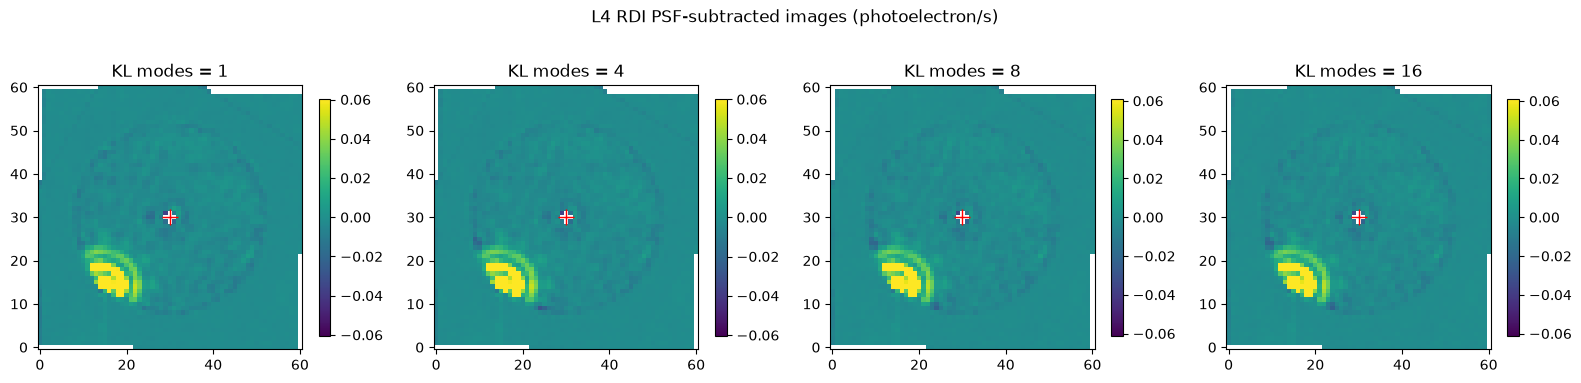

In [19]:
with fits.open(l4_files[0]) as hdul:
    hdul.info()
    l4_data = hdul[1].data
    hdr = hdul[1].header
print('DATALVL:', hdr['DATALVL'], '| BUNIT:', hdr['BUNIT'])
print('PSFPARAM:', hdr['PSFPARAM'])
print('CT cal:', hdr['CTCALFN'], '| flux cal:', hdr['FLXCALFN'])

klmodes = [hdr[f'KLMODE{i}'] for i in range(l4_data.shape[0])]
fig, axes = plt.subplots(1, len(klmodes), figsize=(4 * len(klmodes), 4))
for ax, img, kl in zip(np.atleast_1d(axes), l4_data, klmodes):
    vmax = np.nanpercentile(np.abs(img), 99)
    im = ax.imshow(img, origin='lower', cmap='viridis', vmin=-vmax, vmax=vmax)
    ax.plot(hdr['STARLOCX'], hdr['STARLOCY'], 'r+', ms=12)
    ax.set_title(f'KL modes = {kl}')
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.suptitle('L4 RDI PSF-subtracted images (photoelectron/s)')
plt.tight_layout()

### Notes

- **Mock calibrations.** The astrometric, core-throughput and flux calibrations are placeholders, as in the e2e tests. If real cal products are available, you should replace the placeholders with the paths to the real files before running the DRP.
- **Satellite-spot geometry.** The default NFOV spot separation assumed by `find_star` is 6.5 λ/D. If your data use a different separation or angles, you will need to pass updated `satellite_spot_parameters` to the `find_star` function. See details in the [function description](https://github.com/snhasler/corgidrp/blob/d941f0a123973ec2a48ad724b57914f86cad47b4/corgidrp/l3_to_l4.py#L246). 